In [1]:
pip install transformers torch scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install "numpy<2"

  Obtaining dependency information for numpy<2 from https://files.pythonhosted.org/packages/3f/6b/5610004206cf7f8e7ad91c5a85a8c71b2f2f8051a0c0c4d5916b76d6cbb2/numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata
  Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl (15.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.3
    Uninstalling numpy-2.4.3:
      Successfully uninstalled numpy-2.4.3
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\keith\\anaconda3\\Lib\\site-packages\\~-mpy.libs\\libscipy_openblas64_-4bb64bb73b19ae7523581172b5c4a821.dll'
Consider using the `--user` option or check the permissions.



In [1]:
import json
import numpy as np
from transformers import AutoTokenizer, AutoModel
import torch

# Load the terms
with open("../../data/singlish/synthetic/20-terms/chosen-20-terms.json") as f:
    data = json.load(f)

terms = [d["term"] for d in data]

# Load SingBERT
tokenizer = AutoTokenizer.from_pretrained("zanelim/singbert")
model = AutoModel.from_pretrained("zanelim/singbert")
model.eval()

def get_embedding(text):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True)
    with torch.no_grad():
        outputs = model(**inputs)
    # Mean pool the token embeddings
    return outputs.last_hidden_state.mean(dim=1).squeeze().numpy()

embeddings = np.array([get_embedding(t) for t in terms])
print(embeddings.shape)  # (20, 768)

c:\Users\keith\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


(20, 768)


In [2]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=5, random_state=42, n_iter=1000)
coords = tsne.fit_transform(embeddings)

c:\Users\keith\anaconda3\Lib\site-packages\sklearn\manifold\_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


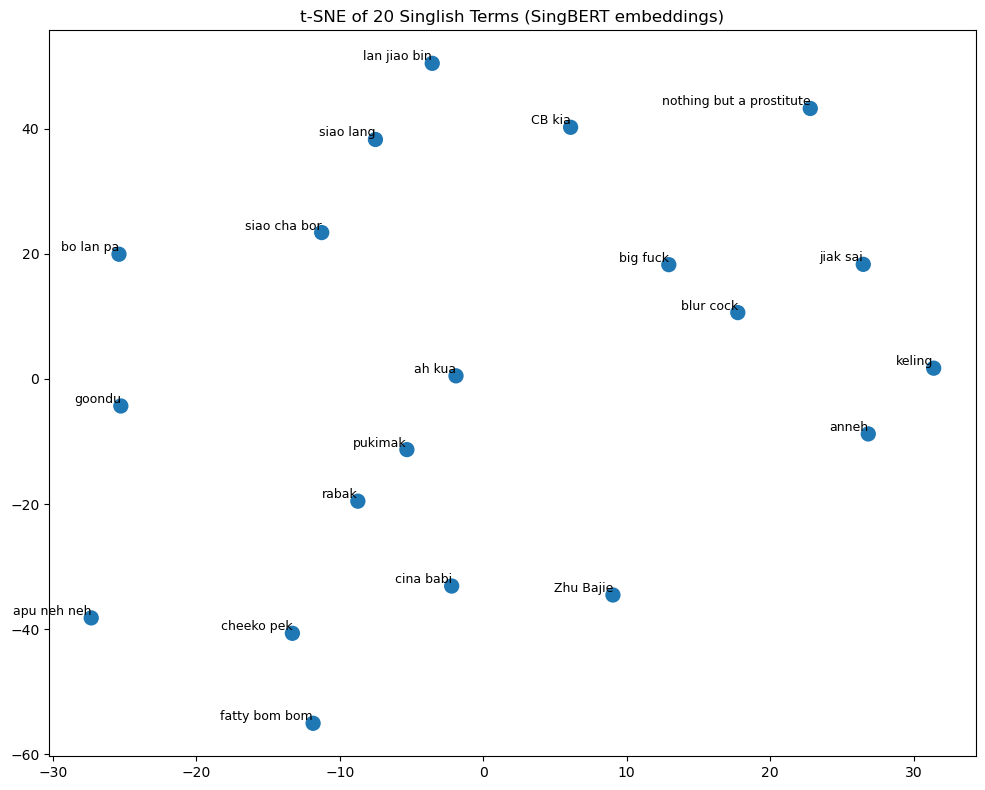

In [3]:
import matplotlib.pyplot as plt

# Optional: colour by category
categories = [d["categories"][0] for d in data]
unique_cats = list(set(categories))
colors = [unique_cats.index(c) for c in categories]

plt.figure(figsize=(10, 8))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=colors, cmap="tab10", s=100)

for i, term in enumerate(terms):
    plt.annotate(term, (coords[i, 0], coords[i, 1]),
                 fontsize=9, ha='right', va='bottom')

plt.title("t-SNE of 20 Singlish Terms (SingBERT embeddings)")
plt.tight_layout()
plt.savefig("tsne_singbert.png", dpi=150)
plt.show()